# Kryptonite-20, -30 and -40: Experiments for H1 to H3

This notebook reproduces every Kryptonite-n result in the report: Table 2, Figure 1 (the learning curves) and the numbers quoted in Sections 4.1 and 5.3. Each section names the hypothesis of Section 3.1 that it tests.

The code is in one script per section (`exp1_degree.py`, `exp2_from_scratch.py`, `exp3_weighted_kernel.py`, `exp4_data_size.py`, `final_pipeline.py`, `energy_report.py`), with the shared parts in `utils.py` (settings, data, splits, cross-validation, result cache, energy measurement) and `models.py` (the models). Each script also runs on its own, in this order, e.g. `python exp1_degree.py`. Results are cached in `exp_cache/` (git-ignored) so an interrupted run resumes; delete it for a fresh run. `KRYP_QUICK=1` runs a dry run on 3,000 rows whose numbers mean nothing. Needs scikit-learn and `codecarbon` (tested with 3.3.2), which measures the energy. A full run took 6.9 hours on an Intel i9-14900HX and needs about 5 GB of free memory for MANBAT's kernel matrix at 32,000 rows.

In [1]:
import utils
import exp1_degree
import exp2_from_scratch
import exp3_weighted_kernel
import exp4_data_size
import final_pipeline
import energy_report

print(
    "QUICK dry run" if utils.QUICK else "Full run",
    f"- {utils.K}-fold CV on 80% of the rows, 20% test set",
)

Full run - 5-fold CV on 80% of the rows, 20% test set


## Data and Protocol (Section 3.2)

Every model except the baseline and one MLP ablation uses the sign of each input; the noise (sd 0.1) is far too small to flip a sign, which `check_protocol` checks. For each n, a stratified 20% of the labelled rows is the test set and the other 80% is split into 5 stratified folds. Every choice, the hyperparameters of each model and the final model, is the one with the highest mean validation accuracy. Only then is each model's chosen setting refitted on all 80% and scored once on the test set; no choice uses these scores.

In [2]:
utils.check_protocol()

Data and splits (all checks passed)
                                       n = 20  n = 30  n = 40
-------------------------------------  ------  ------  ------
Labelled rows                          12,000  20,000  32,000
Test set (20%)                          2,400   4,000   6,400
Per fold (5 folds): training rows       7,680  12,800  20,480
                      validation rows   1,920   3,200   5,120
Positive labels                         49.6%   49.9%   49.8%
Noise sd (input minus its sign)         0.100   0.100   0.100


## Experiment 1: The Paper's Polynomial Models (H1)

*H1: their kernel fits nearly all of its training rows yet scores far below 90% on validation rows.*

- The paper's baseline: logistic regression on all monomials of degree at most 2 of the raw inputs, `C = 0.85`, fitted by SAG for 100 iterations, as in the paper's code.
- The paper's kernel on the signs: the inner product of all monomials of degree at most d, normalised so that k(x, x) = 1 as in the paper, `C = 0.85`, plus an unpenalised intercept, trained by L-BFGS for at most 500 iterations. At degree 10, the highest the paper reports, and at degree 2n, where it can represent every function of the signs; its training accuracy is recorded too.

`test_kernel` first checks that our kernel equals the inner product of scikit-learn's `PolynomialFeatures` and that our solver agrees with scikit-learn's logistic regression.

In [3]:
exp1_degree.run()
exp1_degree.table()

kernel tests passed
CV accuracy (%, mean ± sd over folds); the kernel uses C = 0.85
                                        n = 20      n = 30      n = 40
----------------------------------  ----------  ----------  ----------
Baseline (degree 2, raw inputs)     54.4 ± 1.0  53.2 ± 1.1  53.1 ± 0.3
Their kernel, degree 10             59.0 ± 1.0  54.9 ± 0.7  53.8 ± 0.8
Their kernel, degree 2n             57.2 ± 0.6  50.5 ± 0.3  50.2 ± 0.0
    training accuracy at degree 2n       100.0       100.0       100.0


## Experiment 2: Models Trained From Scratch (H2)

*H2: Kryptonite-n can be learned to over 90%.*

- A random forest of 200 trees; CV chooses the share of inputs tried per split from {1/√n, 0.5, 1} and the minimum leaf size from {1, 5}.
- An MLP with KryptoNet-40's architecture (four hidden layers of 512, ReLU) and n inputs, trained from scratch by Adam with L2 penalty α = 10⁻² for at most 200 epochs, stopping once accuracy on a held-out 10% of its training rows has not improved for 15 epochs; its other settings are scikit-learn's defaults.

In [4]:
exp2_from_scratch.run_models()
exp2_from_scratch.table_models()

Trained from scratch: CV accuracy (%, mean ± sd over folds)
                                            n = 20      n = 30      n = 40
--------------------------------------  ----------  ----------  ----------
Random forest                           82.4 ± 2.3  78.4 ± 2.8  78.6 ± 2.4
    chosen: inputs per split, min leaf      1.0, 5      1.0, 5      1.0, 5
MLP                                     93.1 ± 0.7  94.3 ± 0.9  94.9 ± 0.6


### Ablations of the MLP

On the first three folds, one change at a time, each compared fold by fold with the MLP above: the raw inputs instead of their signs; one hidden layer of 512; four hidden layers of 64.

In [5]:
exp2_from_scratch.run_ablations()
exp2_from_scratch.table_ablations()

MLP ablations, on folds 1, 2, 3 of 5 (mean ± sd)
                                            n = 20       n = 30       n = 40
-------------------------------------  -----------  -----------  -----------
Accuracy (%)
    MLP (four hidden layers of 512)     92.7 ± 0.7   94.2 ± 1.3   94.7 ± 0.7
    Raw inputs instead of their signs   92.1 ± 0.7   93.8 ± 0.5   94.3 ± 0.1
    One hidden layer of 512             85.5 ± 0.7   78.5 ± 1.4   73.5 ± 0.4
    Four hidden layers of 64            73.2 ± 1.8   63.1 ± 1.3   65.6 ± 2.3
Difference from the MLP (points)
    Raw inputs instead of their signs   -0.6 ± 0.1   -0.4 ± 1.6   -0.3 ± 0.6
    One hidden layer of 512             -7.2 ± 1.0  -15.8 ± 2.7  -21.2 ± 0.4
    Four hidden layers of 64           -19.5 ± 2.3  -31.1 ± 2.4  -29.1 ± 3.0


## Experiment 3: MANBAT (H2)

MANBAT is logistic regression with the kernel

$$k_\omega(x, x') = \left(\frac{1 + \sum_j \omega_j x_j x'_j}{1 + \sum_j \omega_j}\right)^d,$$

so that k(x, x) = 1, plus an unpenalised intercept. In each fold, a random forest (200 trees, all inputs considered at each split, at least 5 rows per leaf: the setting Experiment 2 chose at every n) is fitted on a stratified 75% of the training rows. ωⱼ is the drop in its accuracy on the other 25% when input j is shuffled, averaged over 5 shuffles; negative drops are set to 0 and the largest is scaled to 1. CV chooses d ∈ {6, 10, 15} and C ∈ {10, 100}. The same kernel with every ωⱼ = 1 (C = 10) shows what the weights add. Both are trained by L-BFGS until the objective improves by less than a relative 10⁻⁶, for at most 3,000 iterations. The first table shows how the weights concentrate on a few inputs.

In [6]:
exp3_weighted_kernel.run()
exp3_weighted_kernel.table_weights()
exp3_weighted_kernel.table_kernels()

MANBAT's input weights: one random forest per training fold
                                                     n = 20  n = 30  n = 40
---------------------------------------------------  ------  ------  ------
10 largest weights on the same inputs in every fold     yes     yes     yes
Share of the total weight on those 10 inputs          98.1%   98.2%   98.2%
Inputs with weight 0 (left out of the kernel)           4.0    10.2    14.0
Negative importances are set to 0, then the largest weight is scaled to 1; mean over folds.
n = 20: the 10 inputs: 0, 1, 2, 4, 5, 7, 9, 10, 12, 15
n = 30: the 10 inputs: 2, 5, 10, 11, 14, 17, 19, 20, 26, 28
n = 40: the 10 inputs: 6, 7, 12, 15, 21, 24, 25, 30, 36, 39
MANBAT and the equal-weight kernel: CV accuracy by degree (%, mean ± sd over folds)
                                                n = 20      n = 30      n = 40
------------------------------------------  ----------  ----------  ----------
Equal weights (C = 10)
    degree 6                

## Experiment 4: Amount of Training Data (H3, Figure 1)

*H3: held-out accuracy rises as the number of training rows grows from 250 to 4,000.*

MANBAT, the baseline, the random forest and the MLP, each at its CV-best setting, are trained on random subsets of 250, 500, 1,000, 2,000 and 4,000 of the 80% non-test rows (three subsets per size, nested across sizes) and scored on the test set; the last point of each curve is the model's test score in Table 2, a refit on all non-test rows. Nothing is chosen with these scores. MANBAT recomputes its weights on each subset, and its C is multiplied by (all non-test rows / rows used) so that λ stays at its value in that final refit; the baseline keeps the paper's `C = 0.85`, as in the paper's own experiment.

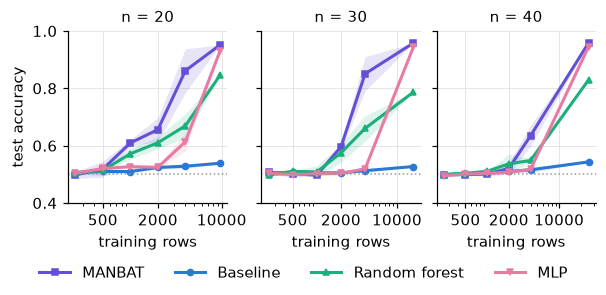

Learning curves: test accuracy (%), mean over 3 random subsets
                    n = 20  n = 30  n = 40
------------------  ------  ------  ------
250 training rows
    MANBAT            49.8    50.7    49.9
    Baseline          50.6    50.1    49.9
    Random forest     50.6    49.8    49.9
    MLP               50.4    50.4    49.5
4000 training rows
    MANBAT            86.2    85.1    63.5
    Baseline          52.8    51.3    51.6
    Random forest     66.9    66.0    54.8
    MLP               61.4    51.9    51.7
all non-test rows
    MANBAT            95.2    95.8    95.9
    Baseline          53.9    52.7    54.3
    Random forest     84.7    78.7    83.0
    MLP               93.2    94.4    94.5
Figure: the same means, shaded one sd over the subsets; the last point of each curve is the model's
test score in Table 2 (one refit on all non-test rows); dotted line at 50%.


In [7]:
curves = exp4_data_size.run_learning_curves()
exp4_data_size.fig_learning_curves(curves)
exp4_data_size.table_learning_curves(curves)

## Final Model, Controls and Test Scores (H2, Table 2)

The final model per n is the one with the highest CV mean. Two controls on the first three folds must score about 50%: the final model with permuted training labels (otherwise label information leaks), and MANBAT with its weights moved to the wrong inputs, the largest on the least important (otherwise the weights are not what makes it work). The test interval is Section 2.5 of the report: with probability at least 95%, the true accuracy is within ε = √(ln(2/0.05) / (2m)) of the accuracy on m test rows. `check_caps` lists every fit that stopped at its iteration cap. The last table is Table 2 of the report: every model's CV-best setting, with its CV accuracy and its test accuracy after a refit on all 80%.

In [8]:
final = final_pipeline.choose_final()
final_pipeline.run_controls(final)
final_pipeline.table_final(final)
utils.check_caps()
final_pipeline.table1(final)


Final model: accuracy (%)
                                                          n = 20           n = 30           n = 40
-----------------------------------------------  ---------------  ---------------  ---------------
Final model (highest CV mean)                             MANBAT           MANBAT           MANBAT
    setting                                      degree 15, C 10  degree 15, C 10  degree 15, C 10
CV accuracy (mean ± sd over folds)                    95.4 ± 0.8       96.1 ± 0.4       96.0 ± 0.2
Test accuracy                                               95.2             95.8             95.9
    test rows m                                             2400             4000             6400
    epsilon (Section 2.5, delta = 0.05), points              2.8              2.1              1.7
    true accuracy at least, with prob. 95%                  92.4             93.7             94.2
Control: permuted training labels                           49.4             50.3 

## Hidden-Set Predictions

The final model is refitted on all labelled rows and predicts the hidden rows. As their labels are unknown, the predictions must agree with those of the best model of another kind that scores above 90% in CV (the MLP): two models with error rates e₁ and e₂ disagree on at most e₁ + e₂ of the rows, so a lower agreement (with 2 points of slack) stops the notebook. Then `hiddenlabels/y_predicted_{20,30,40}.npy` are written and checked with the course's `check_submission.py`.

In [9]:
final_pipeline.predict_hidden(final)

n = 20: MANBAT, degree 15, predicted positive rate 49.9%; agrees with MLP on 98.9% (must be ≥ 86.5%)
n = 30: MANBAT, degree 15, predicted positive rate 50.1%; agrees with MLP on 99.2% (must be ≥ 88.4%)
n = 40: MANBAT, degree 15, predicted positive rate 50.4%; agrees with MLP on 99.0% (must be ≥ 88.9%)
OK    y_predicted_20.npy
OK    y_predicted_30.npy
OK    y_predicted_40.npy


## Energy and Emissions (Section 5.3)

CodeCarbon measured the CPU energy of every result while it was computed, from the processor's own counters (the whole package, so other programs should be closed). No model uses the GPU, so no GPU energy is counted; RAM is not measured. If the CPU counters cannot be read, nothing is reported. Emissions use the UK's 2025 average for electricity consumed, including grid losses, 143.96 g CO2e per kWh (DESNZ), as in the LoRA notebook.

In [10]:
energy_report.carbon_report()

Measured CPU energy by experiment
                     hours  CPU Wh  g CO2e
-------------------  -----  ------  ------
Baseline (degree 2)   0.06     0.7     0.1
Their kernel          0.08     1.4     0.2
Random forest         0.04     0.7     0.1
MLP 4×512             1.96    30.9     4.4
Equal-weight kernel   0.14     2.3     0.3
MANBAT                2.68    63.9     9.2
MLP ablations         0.96    17.6     2.5
Learning curves       0.24     4.4     0.6
MANBAT: bit weights   0.04     0.9     0.1
Controls              0.25     5.5     0.8
Test scores           0.21     4.5     0.6
Hidden-set refits     0.27     5.4     0.8
Total                 6.93   138.2    19.9
CPU: Intel(R) Core(TM) i9-14900HX; energy read from its own counters (windows_emi).
Every model runs on the CPU only, so no GPU energy is counted; RAM and screen are not measured.
g CO2e at 143.96 g per kWh (DESNZ, UK 2025 average, including grid losses).
